# Coarse-scale dynamics from deterministic toy models

This notebook runs the whole Mori-Zwanzig pipeline of the package on toy models whose fine-scale dynamics are
**deterministic**, but whose initial conditions are **random**. Each model gives an ensemble of trajectories, and from
it we learn an effective, stochastic dynamics at several coarser scales.

**The pipeline**

1. **Simulate** `n_batch` trajectories $u_b(t, x)$ from random initial states: a batched `Field` of shape
   `(batch, time, space)`.
2. **Coarse-grain** with a sharp spectral cutoff, `BlockCutoffFilter(block_size = 2**n)`. Level $n$ keeps the Fourier
   modes $|k| < k_{\max} = \pi / (2^n \, dx)$ and puts them on a grid $2^n$ times coarser.
3. **Fit** at every level (`mori_zwanzig_data`). With $L g(t) = g(t+1) - g(t)$ the one-step increment, $P$ the projection
   onto the resolved operators $O_i(u)$ and $Q = 1 - P$:

$$
u_n[t+1] - u_n[t] \;=\; \underbrace{P L u_n}_{\text{Markov: } \sum_i A_i O_i(u_n)}
\;+\; \underbrace{Q L u_n}_{\text{residual}},
\qquad
Q L u_n[b, t] \;\approx\; \gamma_n(t)\, \underbrace{P L Q L u_n[b, t]}_{\text{memory: } \sum_i B_i O_i(u_n)} \;+\; \text{noise}_b[t].
$$

4. **Assemble** the effective dynamics `EffectiveDynamics` at every level,

$$
u_n[t+1] - u_n[t] = \sum_i \big(A_i + \gamma_n(t) B_i\big)\, O_i(u_n[t]) + \text{noise}[t],
$$

   and the training tables `ratio_data` ($\gamma_n(t)$ with bootstrap spread) and `noise_data` (noise variance per mode).
5. **Check** the dynamics on a **held-out** ensemble: does it predict the true coarse increments?

Three details of the method matter for everything below:

* $P$ is estimated **only on the initial states** $u[:, 0]$ (batch averages at $t = 0$), and then applied at every time.
  So a mode must carry variance at $t = 0$, or its projection is ill-conditioned. This is why our initial conditions are
  broadband; section 5 shows what happens otherwise.
* Because of that, the fitted dynamics describe **this ensemble's evolution from its random initial states** over the
  recorded window, a transient. They are not a coarse-grained model of, say, Burgers in a statistically steady state.
* There is **one** memory ratio $\gamma_n(t)$ per level and time, shared by every mode and batch member, and
  $\gamma_n(0) = 0$ exactly.

**The toy models**

| model | equation | what it tests |
|---|---|---|
| 1. Heat equation | $u_t = \nu u_{xx}$ | linear and translation invariant: modes don't interact, so the coarse dynamics is **exactly** Markov |
| 2. Burgers | $u_t + u u_x = \nu u_{xx}$ | nonlinear: scales interact, so coarse-graining leaves a residual; choice of the operator basis |
| 3. Non-uniform advection | $u_t = \nu u_{xx} + a \cos(x)\, u_x$ | linear, but couples $k$ to $k \pm 1$: resolved and unresolved modes exchange information, a clean case for memory |

Section 7 compares the memory ratio with a **lagged kernel** fitted on past states.

In [39]:
import sys

sys.path.append("../src")

import numpy as np
import scipy.linalg
import matplotlib.pyplot as plt

from core.coarse_graining.filter import BlockCutoffFilter
from core.data.base import Field
from core.operators.base import Identity, Operator, OperatorBasis
from core.rgflow.memory import mori_zwanzig_data, noise_data, ratio_data

# one blue, light -> dark, for the filter levels (ordered); blue / orange / black for Markov / with memory / truth
LEVEL_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#1c5cab", 4: "#0d366b"}
MARKOV, MEMORY, TRUTH, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "lines.linewidth": 2,
    "legend.frameon": False,
})

## 1. Setup: grid, initial conditions and solvers

A periodic domain $[0, 2\pi)$ with $N = 128$ points, so the wavenumbers are integers $k = -63, \dots, 64$. We record
`N_TIME = 16` states, `DT = 0.05` apart, with viscosity $\nu = 0.08$ for all three models. Each solver integrates
exactly or with many small sub-steps; only the recorded states enter the pipeline.

**Initial conditions.** Random-phase fields with energy spectrum $E(k) \propto k^2 / (1 + (k/k_0)^2)^2$: most energy
near $k_0 = 3$, and a $k^{-2}$ tail that keeps **every resolved mode populated at $t = 0$**. The rms of $u$ is 1.2, so
the Burgers eddy turnover time $1 / (k_0 u_{\rm rms}) \approx 0.28$ is well inside the recorded window of $0.75$: the
nonlinearity has time to act.

In [40]:
L, N = 2 * np.pi, 128
dx = L / N
x = np.arange(N) * dx
k = 2 * np.pi * np.fft.fftfreq(N, d=dx)  # integer wavenumbers on [0, 2 pi)

DT, N_TIME = 0.05, 16
TIMES = np.arange(N_TIME) * DT
NU = 0.08
N_TRAIN, N_TEST = 600, 300
N_LEVELS = 4


def random_initial_states(rng, n_batch, k0=3.0, amplitude=1.2, spectrum=None):
    # default E(k) ~ k^2 / (1 + (k / k0)^2)^2: peaked near k0, with a k^-2 tail; amplitude is the rms of u
    kk = np.abs(k)
    if spectrum is None:
        spectrum = (kk > 0) * kk**2 / (1 + (kk / k0) ** 2) ** 2
    modes = np.sqrt(spectrum) * rng.normal(size=(n_batch, N)) * np.exp(2j * np.pi * rng.random((n_batch, N)))
    u = np.real(np.fft.ifft(modes, axis=-1))
    return amplitude * u / u.std()


def heat(u0):
    # exact: every Fourier mode decays by exp(-nu k^2 DT) per recorded step
    decay = np.exp(-NU * k**2 * DT)
    u = [u0]
    for _ in range(N_TIME - 1):
        u.append(np.real(np.fft.ifft(decay * np.fft.fft(u[-1], axis=-1), axis=-1)))
    return np.stack(u, axis=1)


def burgers(u0, h=1e-3):
    # pseudo-spectral, 2/3-rule dealiasing, RK4 with step h
    dealias = np.abs(k) < (2 / 3) * np.abs(k).max()

    def rhs(uk):
        u = np.real(np.fft.ifft(uk, axis=-1))
        return -0.5j * k * np.fft.fft(u * u, axis=-1) * dealias - NU * k**2 * uk

    uk, u = np.fft.fft(u0, axis=-1), [u0]
    for _ in range(N_TIME - 1):
        for _ in range(round(DT / h)):
            k1 = rhs(uk)
            k2 = rhs(uk + h / 2 * k1)
            k3 = rhs(uk + h / 2 * k2)
            k4 = rhs(uk + h * k3)
            uk = uk + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        u.append(np.real(np.fft.ifft(uk, axis=-1)))
    return np.stack(u, axis=1)


def nonuniform_advection(u0, a=1.0):
    # linear, so one recorded step is the exact matrix exponential of nu d_xx + a cos(x) d_x
    F = np.fft.fft(np.eye(N), axis=0)
    d1 = np.real(np.linalg.solve(F, np.diag(1j * k) @ F))
    d2 = np.real(np.linalg.solve(F, np.diag(-(k**2)) @ F))
    step = scipy.linalg.expm(DT * (NU * d2 + a * np.diag(np.cos(x)) @ d1))
    u = [u0]
    for _ in range(N_TIME - 1):
        u.append(u[-1] @ step.T)
    return np.stack(u, axis=1)


def ensemble(model, seed, n_batch, **initial):
    u = model(random_initial_states(np.random.default_rng(seed), n_batch, **initial))
    return Field(values=u, scale=dx, batched=True, time=TIMES)


models = {"heat": heat, "burgers": burgers, "nonuniform advection": nonuniform_advection}
train = {name: ensemble(model, seed=0, n_batch=N_TRAIN) for name, model in models.items()}
test = {name: ensemble(model, seed=1, n_batch=N_TEST) for name, model in models.items()}

u_rms = train["burgers"].values[:, 0].std()
print(f"rms of u at t = 0: {u_rms:.2f};  eddy turnover time 1 / (k0 u_rms) = {1 / (3 * u_rms):.2f};  "
      f"recorded window: {TIMES[-1]:.2f}")

rms of u at t = 0: 1.20;  eddy turnover time 1 / (k0 u_rms) = 0.28;  recorded window: 0.75


### What the trajectories look like

Top: one trajectory of each model in space-time. Bottom: the ensemble-mean energy spectrum $\langle |\hat u_k|^2\rangle$
at the first and last recorded time (dashed: the cutoffs of levels 1-4).

* **Heat:** only damps; at $t = 0.75$ the spectrum falls off like $e^{-2\nu k^2 t}$.
* **Burgers:** steepens the field into **fronts**, steep drops of $u$ that move with the flow (the tilted edges in the
  space-time plot). Its spectrum at $t = 0.75$ keeps far more energy at high $k$ than the heat equation's (about
  $10^{-6}$ at $k = 16$, where the heat spectrum is already below $10^{-14}$): the nonlinearity keeps feeding the high
  modes that viscosity drains. The numbers below the plot confirm the fronts: the skewness of $u_x$ goes from $0$ to
  about $-2.3$. A front is a steep *negative* gradient, so it gives $u_x$ a long negative tail.
* **Non-uniform advection:** squeezes and stretches the field around the zeros of $\cos x$. It is linear, so its
  gradient skewness stays at $0$.

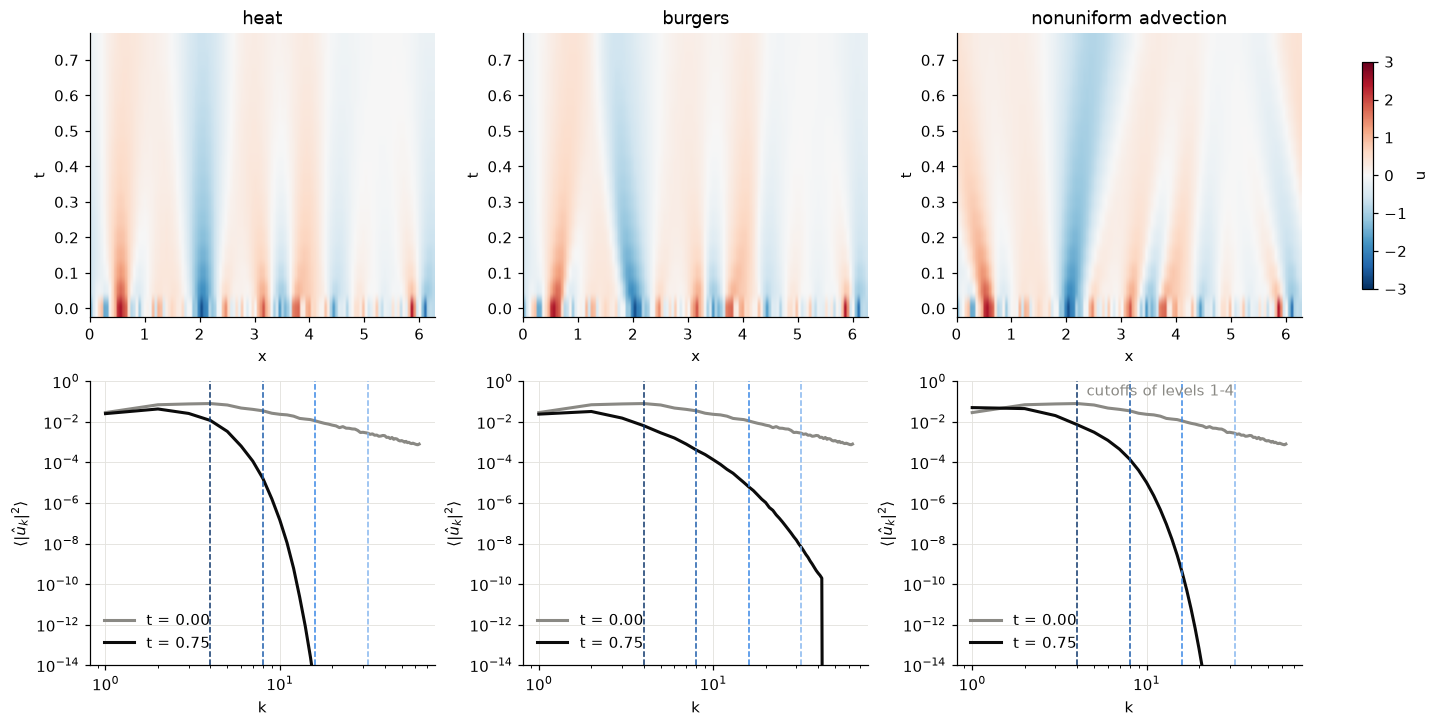

                  heat: skewness of u_x at t = 0.00: -0.01,  at t = 0.75: -0.02
               burgers: skewness of u_x at t = 0.00: -0.01,  at t = 0.75: -2.27
  nonuniform advection: skewness of u_x at t = 0.00: -0.01,  at t = 0.75: -0.02


In [41]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), constrained_layout=True)
for col, (name, field) in enumerate(train.items()):
    ax = axes[0, col]
    image = ax.imshow(
        field.values[0], aspect="auto", origin="lower", cmap="RdBu_r", vmin=-3, vmax=3,
        extent=[0, L, TIMES[0] - DT / 2, TIMES[-1] + DT / 2],
    )
    ax.set(title=name, xlabel="x", ylabel="t")
    ax.grid(False)

    ax = axes[1, col]
    spectrum = np.mean(np.abs(np.fft.fft(field.values, axis=-1, norm="forward")) ** 2, axis=0)
    positive = slice(1, N // 2)
    ax.loglog(k[positive], spectrum[0, positive], color=MUTED, label=f"t = {TIMES[0]:.2f}")
    ax.loglog(k[positive], spectrum[-1, positive], color=TRUTH, label=f"t = {TIMES[-1]:.2f}")
    for level, color in LEVEL_COLORS.items():
        ax.axvline(N / 2**(level + 1), color=color, linewidth=1, linestyle="--")
    ax.set(xlabel="k", ylabel=r"$\langle |\hat u_k|^2 \rangle$", ylim=(1e-14, 1))
    ax.legend(loc="lower left")
fig.colorbar(image, ax=axes[0, :], shrink=0.8, label="u")
axes[1, 2].text(N / 2**2, 2e-1, "cutoffs of levels 1-4", color=MUTED, ha="right")
plt.show()

# fronts: Burgers fronts are steep drops of u, so the gradient u_x gets a long negative tail (skewness < 0);
# random-phase initial states have skewness ~ 0
for name, field in train.items():
    ux = np.real(np.fft.ifft(1j * k * np.fft.fft(field.values, axis=-1), axis=-1))
    skew = [np.mean(ux[:, t] ** 3) / np.mean(ux[:, t] ** 2) ** 1.5 for t in (0, -1)]
    print(f"{name:>22}: skewness of u_x at t = {TIMES[0]:.2f}: {skew[0]:+.2f},  at t = {TIMES[-1]:.2f}: {skew[1]:+.2f}")

## 2. Coarse-graining

`BlockCutoffFilter(block_size=2**n, odd_grid=True).transform` keeps the modes $|k| < k_{\max}$ and stores them on a
grid with one point per kept mode: 63, 31, 15 and 7 points for levels 1-4. This is exactly what `mori_zwanzig_data`
does internally. Below, one Burgers state at the last time and its four coarse versions. Levels 1-3 still follow the
front near $x \approx 1.5$; level 4 (7 points) keeps only the overall rise and fall.

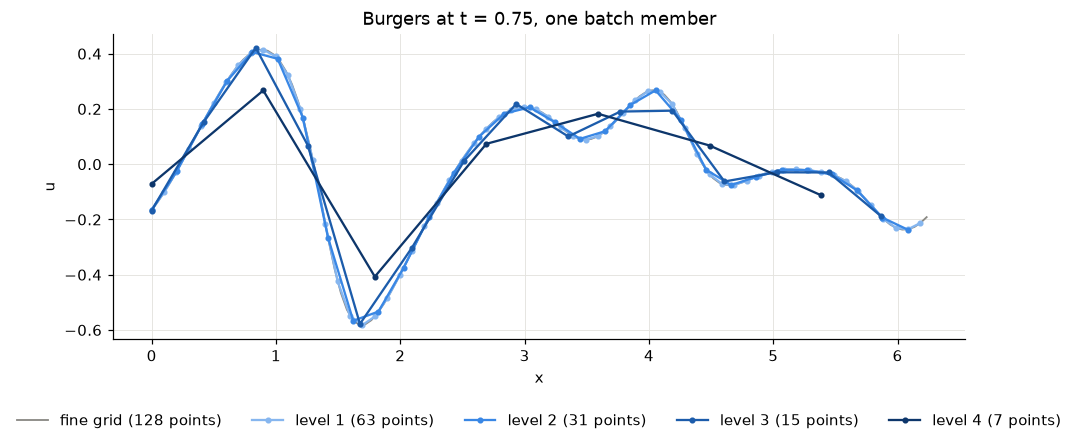

In [42]:
def coarse(field, level):
    # the field filtered at a level, on its coarse grid, as mori_zwanzig_data builds it
    return BlockCutoffFilter(block_size=2**level, odd_grid=True).transform(field.to_fourier()).to_real()


fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(x, train["burgers"].values[0, -1], color=MUTED, linewidth=1.2, label=f"fine grid ({N} points)")
for level, color in LEVEL_COLORS.items():
    c = coarse(train["burgers"], level)
    xc = np.arange(c.spatial_shape[0]) * c.scale[0]
    ax.plot(xc, c.values[0, -1], "o-", color=color, markersize=3, linewidth=1.5,
            label=f"level {level} ({c.spatial_shape[0]} points)")
ax.set(xlabel="x", ylabel="u", title=f"Burgers at t = {TIMES[-1]:.2f}, one batch member")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()

## 3. Fitting and scoring helpers

`mori_zwanzig_data(field, n_levels, basis=..., homogeneous=...)` returns one `MoriZwanzigData` per level, with:

* `residual` $= Q L u_n$ and `memory` $= P L Q L u_n$, as fields of shape `(batch, N_TIME - 2, space)`;
* `markov` ($A_i$) and `memory_couplings` ($B_i$): per operator, one array per kept wavevector;
* `ratio()` $\to \gamma_n(t)$ with its standard error, `noise()` and `noise_var()`;
* `dynamics()` $\to$ the `EffectiveDynamics`, whose `evaluate(states)` gives the Markov drift
  $\sum_i A_i O_i$ and `evaluate(states, memory=True)` adds $\gamma_n(t) \sum_i B_i O_i$ at each state's own time.

We score every level with five numbers:

| score | definition | reads as |
|---|---|---|
| `unexplained` | $\lVert Q L u \rVert / \lVert L u \rVert$ on the training set, over all resolved modes | relative size of what the Markov term misses: the training counterpart of `test markov` |
| `unexpl. \|k\|<=3` | the same, over the modes $\lvert k \rvert \le 3$ only | the fair comparison **between levels**, see below |
| `memory share` | $1 - \lVert Q L u - \gamma P L Q L u \rVert^2 / \lVert Q L u \rVert^2$ | the share of the residual's variance that the memory term explains |
| `test markov` | $\lVert \text{prediction} - L u \rVert / \lVert L u \rVert$ on the held-out set, Markov drift only | relative error of the predicted step |
| `test +memory` | the same with the memory term | |

**Why a second `unexplained`.** Each level is scored on its **own** resolved modes, and the norm is dominated by the
modes with the largest steps, typically those near the level's cutoff. So `unexplained` at two levels compares
different sets of modes. The modes $|k| \le 3$ are resolved at every level (level 4 keeps exactly those), so
`unexpl. |k|<=3` measures how the **same** modes are predicted as the cutoff moves down.

In [43]:
K_COMMON = 3  # |k| <= 3 is resolved at every level (level 4 keeps |k| <= 3)


def states_and_steps(c):
    # the states u[t] and their true increments u[t+1] - u[t] for the N_TIME - 2 times the dynamics covers
    n = len(c.time) - 2
    return c.replace(values=c.values[:, :n], time=c.time[:n]), c.values[:, 1:n + 1] - c.values[:, :n]


def common_modes(values):
    # the Fourier modes |k| <= K_COMMON of values (..., space)
    m = values.shape[-1]
    return np.fft.fft(values, axis=-1, norm="forward")[..., np.abs(np.rint(np.fft.fftfreq(m) * m)) <= K_COMMON]


def score(data, train_field, test_field):
    rows = []
    for d in data:
        _, step = states_and_steps(coarse(train_field, d.level))
        residual, noise = d.residual.values, d.noise().values
        states, true = states_and_steps(coarse(test_field, d.level))
        dynamics = d.dynamics()
        rel = lambda predicted: np.linalg.norm(predicted - true) / np.linalg.norm(true)
        rows.append({
            "level": d.level,
            "points": d.residual.spatial_shape[0],
            "unexplained": np.linalg.norm(residual) / np.linalg.norm(step),
            "unexpl. |k|<=3": np.linalg.norm(common_modes(residual)) / np.linalg.norm(common_modes(step)),
            "memory share": 1 - np.sum(np.abs(noise) ** 2) / np.sum(np.abs(residual) ** 2),
            "test markov": rel(dynamics.evaluate(states).values),
            "test +memory": rel(dynamics.evaluate(states, memory=True).values),
        })
    return rows


def show(rows, title):
    print(title)
    print("".join(f"{key:>16}" for key in rows[0]))
    for row in rows:
        print("".join(f"{value:>16}" if isinstance(value, int) else f"{value:>16.4g}" for value in row.values()))

## 4. Model 1: heat equation, an exact closure

For $u_t = \nu u_{xx}$ every Fourier mode evolves on its own: $\hat u_k(t + \Delta t) = e^{-\nu k^2 \Delta t}\,\hat u_k(t)$.
Filtering only removes modes, so the resolved modes still follow a closed, Markov equation, with the **same** coupling
at every level:

$$A(k) = e^{-\nu k^2 \Delta t} - 1, \qquad Q L u_n = 0.$$

The homogeneous fit (`homogeneous=True`, one small regression per wavevector) should recover $A(k)$ to machine
precision at every level, and leave nothing for the memory.

heat equation, basis [u]
           level          points     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
               1              63       1.538e-15       5.285e-15          0.4283       1.545e-15       1.149e-15
               2              31       2.075e-15       7.249e-15          0.2775       2.048e-15       1.742e-15
               3              15       2.856e-15       6.866e-15          0.1461       2.787e-15       2.569e-15
               4               7       6.742e-15       6.742e-15         0.01658       6.526e-15       6.485e-15


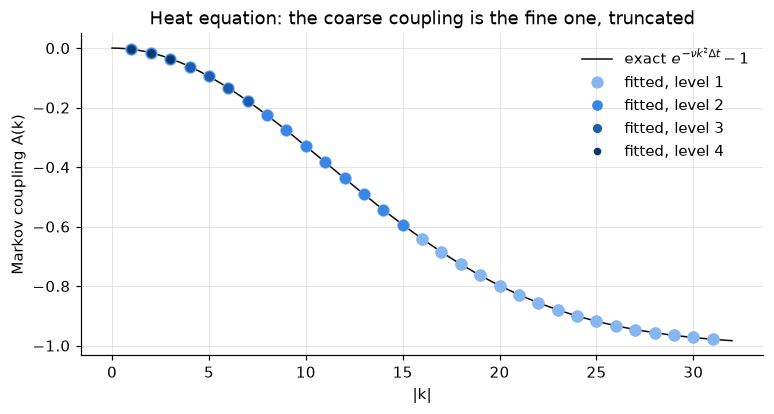

In [44]:
heat_data = mori_zwanzig_data(train["heat"], n_levels=N_LEVELS)
show(score(heat_data, train["heat"], test["heat"]), "heat equation, basis [u]")

fig, ax = plt.subplots(figsize=(8, 3.8))
kk = np.linspace(0, N / 4, 200)
ax.plot(kk, np.exp(-NU * kk**2 * DT) - 1, color=TRUTH, linewidth=1, label=r"exact $e^{-\nu k^2 \Delta t} - 1$")
for d in heat_data:
    kv = d.wavevectors[:, 0]
    keep = kv != 0  # the mean: zero in every initial state, see below
    ax.plot(np.abs(kv[keep]), d.markov["I"][keep, 0].real, "o", color=LEVEL_COLORS[d.level], markersize=8 - d.level,
            label=f"fitted, level {d.level}")
ax.set(xlabel="|k|", ylabel="Markov coupling A(k)", title="Heat equation: the coarse coupling is the fine one, truncated")
ax.legend()
plt.show()

**Reading the result.** The fitted couplings sit on the exact curve at every level, and each level simply stops at its
own cutoff. The residual is about $10^{-15}$ of the step, which is round-off, and the held-out error is round-off too.

The plot leaves out $k = 0$. Our initial states all have zero mean, so the $k = 0$ mode has zero variance at $t = 0$,
and its fitted coupling is an arbitrary number fitted on round-off. This is the "$P$ needs variance at $t = 0$" caveat
in its simplest form. It is harmless here only because the mean stays zero.

The `memory share` column is **meaningless here**: it compares round-off with round-off. The same goes for
$\gamma_n(t)$, a ratio of two round-off-sized numbers. When the residual vanishes, there is no memory to measure.

## 5. Model 2: Burgers, where scales interact

The nonlinear term $u u_x = (u^2/2)_x$ couples modes $p$ and $q$ into mode $p + q$, so the resolved modes are driven by
the unresolved ones and coarse-graining no longer closes. We fit two operator bases:

* **linear** `[u]`: the drift is a linear function of each resolved mode, $A(k)\, \hat u_k$;
* **with the nonlinearity** `[u, -(u^2/2)_x]`, where $-(u^2/2)_x$ is computed from the **coarse** field on the coarse
  grid of each level. It contains every interaction among resolved modes, and none with the unresolved ones: those
  are what the residual has to carry. It is computed with zero-padding (dealiased), so that products of resolved
  modes don't alias back onto the resolved modes; the fine-grid solver is dealiased too.

In [45]:
class Advection(Operator):
    # -(u^2 / 2)_x on the field's own grid, dealiased: u is zero-padded to twice as many points before squaring, so
    # products of resolved modes cannot alias back onto the resolved modes. Keeps the field's domain.
    name = "-(u^2/2)_x"

    def evaluate(self, field):
        u = field.to_real()
        m = u.spatial_shape[0]  # 1D scalar field: space is the last axis
        kx = u.wavenumbers()[0]
        modes = np.rint(kx * u.scale[0] * m / (2 * np.pi)).astype(int)  # integer mode numbers on this grid
        padded = np.zeros(u.values.shape[:-1] + (2 * m,), dtype=complex)
        padded[..., modes % (2 * m)] = np.fft.fft(u.values, axis=-1)
        fine = np.real(np.fft.ifft(padded, axis=-1)) * 2  # u on the padded grid
        square = np.fft.fft(fine**2 / 2, axis=-1)[..., modes % (2 * m)] / 2  # (u^2 / 2)_k back on this grid
        out = u.replace(values=np.real(np.fft.ifft(-1j * kx * square, axis=-1)))
        return out.to_fourier() if field.domain == "fourier" else out


bases = {
    "linear [u]": OperatorBasis([Identity()]),
    "with nonlinearity [u, -(u^2/2)_x]": OperatorBasis([Identity(), Advection()]),
}
burgers_data = {name: mori_zwanzig_data(train["burgers"], n_levels=N_LEVELS, basis=basis) for name, basis in bases.items()}
burgers_scores = {name: score(data, train["burgers"], test["burgers"]) for name, data in burgers_data.items()}
for name, rows in burgers_scores.items():
    show(rows, f"Burgers, basis {name}")
    print()

Burgers, basis linear [u]
           level          points     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
               1              63           0.532          0.7441           0.123          0.5286           0.498
               2              31          0.6473          0.7441          0.1101          0.6437          0.6102
               3              15          0.6908          0.7441         0.04678          0.6788          0.6654
               4               7          0.7441          0.7441         0.04626          0.7444          0.7253

Burgers, basis with nonlinearity [u, -(u^2/2)_x]
           level          points     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
               1              63          0.2114          0.1197          0.2077          0.2114          0.1906
               2              31          0.2041          0.1108          0.1111          0.2015          0.1899
               3    

### How much of the step does each level explain?

Left: what the Markov term misses, relative to the coarse step, per level and basis (training set), over all resolved
modes (solid) and over the modes $|k| \le 3$ that every level resolves (dotted). Right: held-out relative error,
Markov only (solid) and with memory (dashed).

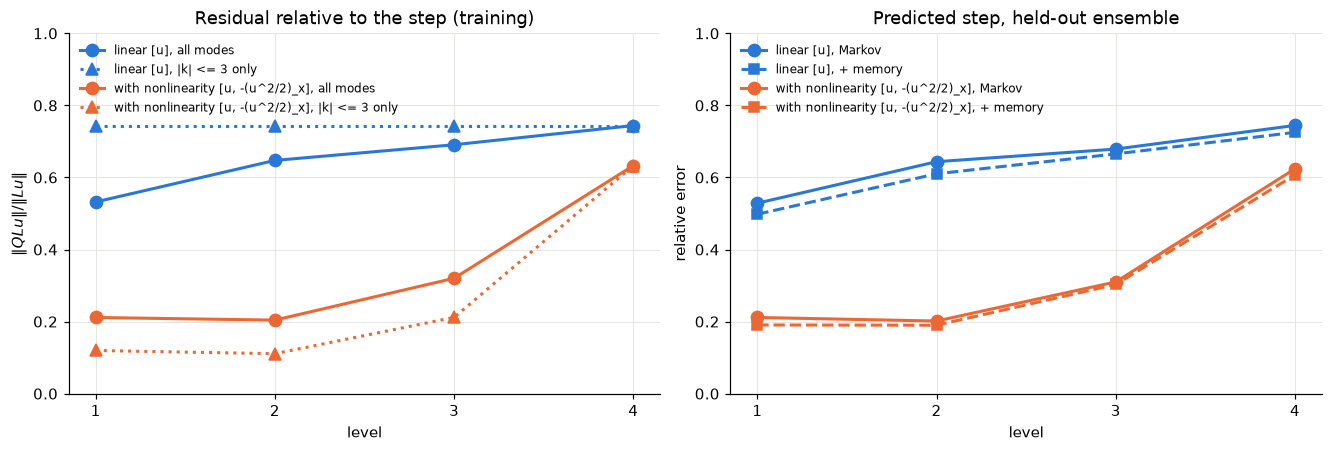

In [46]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
levels = np.arange(1, N_LEVELS + 1)
for (name, rows), color in zip(burgers_scores.items(), [MARKOV, MEMORY]):
    left.plot(levels, [r["unexplained"] for r in rows], "o-", color=color, markersize=8, label=f"{name}, all modes")
    left.plot(levels, [r["unexpl. |k|<=3"] for r in rows], "^:", color=color, markersize=8,
              label=f"{name}, |k| <= 3 only")
    right.plot(levels, [r["test markov"] for r in rows], "o-", color=color, markersize=8, label=f"{name}, Markov")
    right.plot(levels, [r["test +memory"] for r in rows], "s--", color=color, markersize=7, label=f"{name}, + memory")
left.set(xlabel="level", ylabel=r"$\|QLu\| / \|Lu\|$", ylim=(0, 1), xticks=levels,
         title="Residual relative to the step (training)")
right.set(xlabel="level", ylabel="relative error", ylim=(0, 1), xticks=levels,
          title="Predicted step, held-out ensemble")
left.legend(loc="upper left", fontsize=8)
right.legend(loc="upper left", fontsize=8)
plt.show()

**Reading the result.**

* **Linear basis:** over the common modes $|k| \le 3$ (dotted blue), the residual is **exactly the same at every
  level**, 0.744. Removing scales changes nothing for these modes, because the fit for each mode never sees the other
  modes (next subsection). The solid blue curve still rises with the level, but only because each level is scored on
  a different set of modes.
* **Basis with the nonlinearity:** the nonlinear term cuts the residual on the low modes from 0.744 to 0.12 and 0.11
  at levels 1-2. Then it degrades: 0.21 at level 3, 0.63 at level 4. This is the actual cost of coarse-graining. As
  the cutoff approaches $k = 3$, more of the modes that interact with the low ones are removed, and $-(u^2/2)_x$
  computed from the coarse field misses their contribution. At level 4 the cutoff *is* $k = 3$, and little is left.
* **Memory:** it lowers the held-out error at every level, so it generalises, but only a little: from 0.211 to 0.199
  at level 1, and from 0.624 to 0.607 at level 4. It explains between 0.3% and 12% of the residual's variance. One
  scalar $\gamma_n(t)$, shared by all modes, is a very constrained memory model for Burgers.

### The linear basis: the same $A(k)$ at every level

With `homogeneous=True` and the basis `[u]`, $P$ regresses the step's mode $k$ on $\hat u_k(0)$ **alone**, one
wavevector at a time. Filtering doesn't change a resolved mode, so the step's mode $k$ and $\hat u_k$ are the same at
every level, and so is $A(k)$. The plot and the printed gaps (round-off) confirm it: the fitted $A(k)$ at each level is
the same curve, truncated at the level's cutoff. **So with this basis, $A(k)$ carries no information about the
cutoff.** It is a property of the full dynamics, not of coarse-graining.

$A(k)$ lies below the bare viscous term $e^{-\nu k^2 \Delta t} - 1$: on average, a step damps each mode more than
viscosity alone. Over one step, the nonlinearity moves energy out of mode $k$, and part of that loss correlates with
$\hat u_k$. To first order in $\Delta t$ the nonlinear term is uncorrelated with $\hat u_k$ in a random-phase ensemble
(the third moments vanish), so this extra damping is a second-order effect of the finite step, and it is specific to
our initial ensemble.

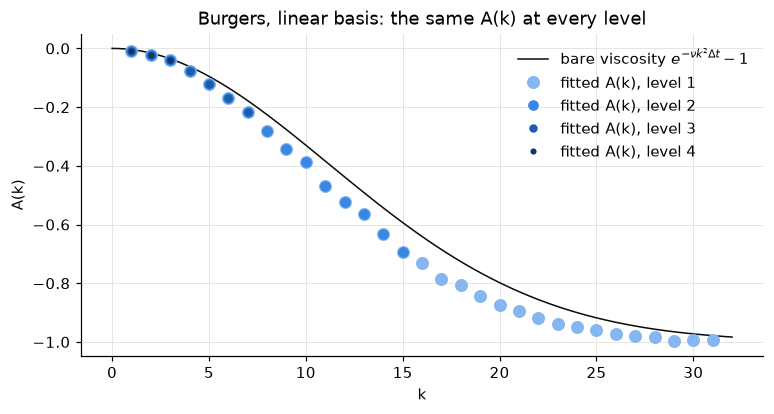

level 2: max over k != 0 of |A_2(k) - A_1(k)| = 2.2e-16
level 3: max over k != 0 of |A_3(k) - A_1(k)| = 1.4e-16
level 4: max over k != 0 of |A_4(k) - A_1(k)| = 1.1e-17


In [47]:
fig, ax = plt.subplots(figsize=(8, 3.8))
kk = np.linspace(0, N / 4, 200)
ax.plot(kk, np.exp(-NU * kk**2 * DT) - 1, color=TRUTH, linewidth=1, label=r"bare viscosity $e^{-\nu k^2 \Delta t} - 1$")
linear = burgers_data["linear [u]"]
for d in linear:
    kv = d.wavevectors[:, 0]
    keep = kv > 0
    ax.plot(kv[keep], d.markov["I"][keep, 0].real, "o", color=LEVEL_COLORS[d.level], markersize=9 - 1.5 * d.level,
            label=f"fitted A(k), level {d.level}")
ax.set(xlabel="k", ylabel="A(k)", title="Burgers, linear basis: the same A(k) at every level")
ax.legend()
plt.show()

# the same check in numbers: A(k) at every level against level 1, for k != 0
level_1 = {kv: a for kv, a in zip(linear[0].wavevectors[:, 0], linear[0].markov["I"][:, 0])}
for d in linear[1:]:
    gap = max(abs(a - level_1[kv]) for kv, a in zip(d.wavevectors[:, 0], d.markov["I"][:, 0]) if kv != 0)
    print(f"level {d.level}: max over k != 0 of |A_{d.level}(k) - A_1(k)| = {gap:.1e}")

### The memory ratio $\gamma_n(t)$

`ratio_data(data, n_bootstrap=...)` collects $\gamma_n(t)$ for every level and time, with a bootstrap over the batch
members (P kept fixed). This table is the training data for a later model of $\gamma$ as a function of time and scale.
The band shows the 5-95% bootstrap range. $\gamma_n(0) = 0$ exactly: at $t = 0$ the residual is orthogonal to
everything $P$ projects onto, and the memory is in that span.

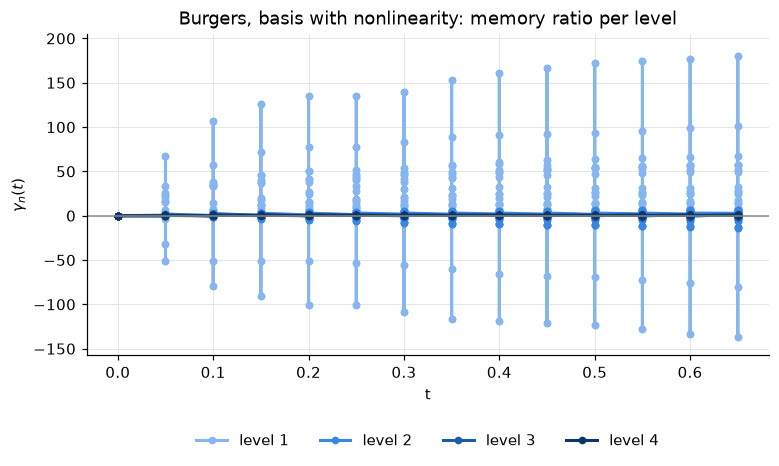

In [48]:
nonlinear = burgers_data["with nonlinearity [u, -(u^2/2)_x]"]
ratios = ratio_data(nonlinear, n_bootstrap=200, seed=0)

fig, ax = plt.subplots(figsize=(8, 3.8))
for level, color in LEVEL_COLORS.items():
    rows = ratios.level == level
    t = ratios.time[rows]
    low, high = np.nanpercentile(ratios.bootstrap[rows].real, [5, 95], axis=1)
    ax.fill_between(t, low, high, color=color, alpha=0.25, linewidth=0)
    ax.plot(t, ratios.ratio[rows].real, "o-", color=color, markersize=4, label=f"level {level}")
ax.axhline(0, color=MUTED, linewidth=1)
ax.set(xlabel="t", ylabel=r"$\gamma_n(t)$", title="Burgers, basis with nonlinearity: memory ratio per level")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()

$\gamma_n(t)$ is well determined (narrow bootstrap bands) and starts at $0$. But it depends strongly on the level and on
time, with no simple ordering. At level 1 it rises to about 3.8. At level 2 it stays near 0 until $t \approx 0.2$,
then grows. At level 3 it peaks near $t = 0.1$ and decays back to 0. One scalar per level and time has to summarise
how very different unresolved scales act on the resolved ones.

### The noise

What the memory does not explain is the noise. `noise_data` gives its variance per Fourier mode, level and time. Below,
at the last time, as a function of $|k|$ (averaged over $\pm k$; $k = 0$, the mean, has no noise). Level 4 is by far
the noisiest, and level 2 is noisier than level 1 at every $|k| \ge 5$: removing more scales leaves more for the noise
to carry. At the lowest modes, levels 1-3 are comparable. The shape within a level is not simple either. At level 1,
the noise peaks around $|k| \approx 13$ and falls off towards the cutoff, where viscosity damps a mode within a
fraction of a step.

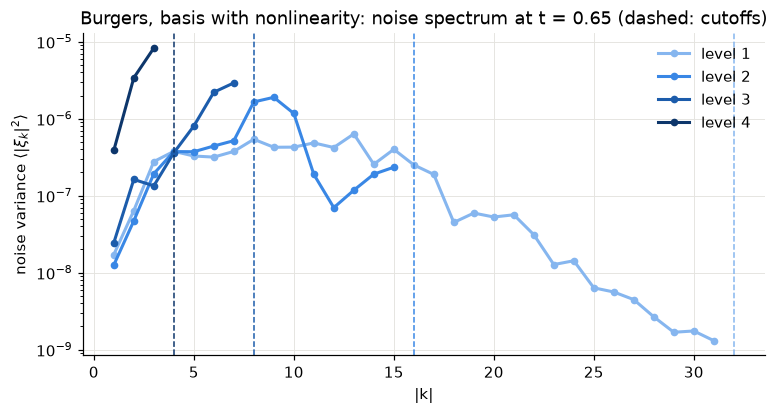

In [49]:
noise = noise_data(nonlinear)
last = noise.time == noise.time.max()

fig, ax = plt.subplots(figsize=(8, 3.8))
for level, color in LEVEL_COLORS.items():
    rows = last & (noise.level == level)
    kabs = np.abs(noise.k[rows, 0])
    ks = np.unique(kabs[kabs > 0])  # the mean is zero in every state, so it has no noise
    variance = [noise.noise_var[rows][kabs == kv].mean() for kv in ks]
    ax.semilogy(ks, variance, "o-", color=color, markersize=4, label=f"level {level}")
    ax.axvline(N / 2**(level + 1), color=color, linewidth=1, linestyle="--")
ax.set(xlabel="|k|", ylabel=r"noise variance $\langle |\xi_k|^2 \rangle$",
       title=f"Burgers, basis with nonlinearity: noise spectrum at t = {noise.time.max():.2f} (dashed: cutoffs)")
ax.legend()
plt.show()

### One prediction, looked at directly

A held-out trajectory at level 2 (31 points): the true coarse step $u_2[t+1] - u_2[t]$ against the predicted drift,
with and without memory, for both bases. The scores above are norms of the gaps you see here.

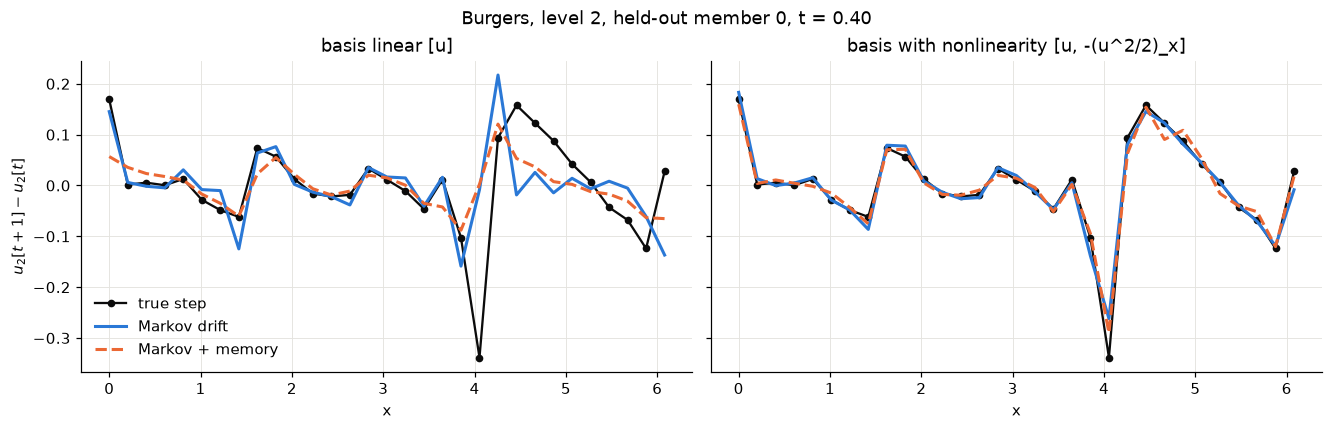

In [50]:
level, t_index, member = 2, 8, 0
c = coarse(test["burgers"], level)
states, true = states_and_steps(c)
xc = np.arange(c.spatial_shape[0]) * c.scale[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True, constrained_layout=True)
for ax, (name, data) in zip(axes, burgers_data.items()):
    dynamics = data[level - 1].dynamics()
    ax.plot(xc, true[member, t_index], "o-", color=TRUTH, markersize=4, linewidth=1.5, label="true step")
    ax.plot(xc, dynamics.evaluate(states).values[member, t_index], color=MARKOV, label="Markov drift")
    ax.plot(xc, dynamics.evaluate(states, memory=True).values[member, t_index], "--", color=MEMORY,
            label="Markov + memory")
    ax.set(xlabel="x", title=f"basis {name}")
axes[0].set_ylabel(rf"$u_{level}[t+1] - u_{level}[t]$")
axes[0].legend()
fig.suptitle(f"Burgers, level {level}, held-out member {member}, t = {TIMES[t_index]:.2f}")
plt.show()

### Why the initial spectrum matters

$P$ is fitted on the initial states only. Here we repeat the Burgers fit (linear basis, levels 1-2) with a **narrow**
initial spectrum, $E(k) \propto k^2 e^{-(k/k_0)^2}$, with the same rms and everything else unchanged. Its high modes are
practically empty at $t = 0$: the variance of mode $k = 31$ is about $10^{-44}$ of the peak, far below what double
precision resolves next to the peak modes. The nonlinearity fills them within a few steps, and $P$ then multiplies
them by coefficients fitted on round-off. The result below: at level 1, the residual is about $10^{11}$ times the
step, and $|A(k)|$ reaches about $10^{12}$. Nothing in the pipeline warns about it.

In [51]:
kk = np.abs(k)
narrow = kk**2 * np.exp(-((kk / 3.0) ** 2))
print(f"narrow spectrum: variance of mode k = 31 relative to the peak: {narrow[31] / narrow.max():.1e}")

narrow_train = ensemble(burgers, seed=0, n_batch=N_TRAIN, spectrum=narrow)
narrow_test = ensemble(burgers, seed=1, n_batch=N_TEST, spectrum=narrow)
narrow_data = mori_zwanzig_data(narrow_train, n_levels=2)
show(score(narrow_data, narrow_train, narrow_test), "Burgers, narrow initial spectrum, basis [u]")
print(f"largest |A(k)|: {max(np.abs(d.markov['I']).max() for d in narrow_data):.1e}")
show(burgers_scores["linear [u]"][:2], "\nfor comparison, broadband initial spectrum, basis [u]")

narrow spectrum: variance of mode k = 31 relative to the peak: 1.2e-44
Burgers, narrow initial spectrum, basis [u]
           level          points     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
               1              63       2.072e+11          0.7314               1       1.892e+11            1258
               2              31           8.922          0.7314          0.9916           8.729          0.8205
largest |A(k)|: 4.3e+12

for comparison, broadband initial spectrum, basis [u]
           level          points     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
               1              63           0.532          0.7441           0.123          0.5286           0.498
               2              31          0.6473          0.7441          0.1101          0.6437          0.6102


## 6. Model 3: non-uniform advection, where memory matters

$u_t = \nu u_{xx} + a\cos(x)\, u_x$ is linear, but $\cos x\, u_x$ moves energy from mode $k$ to modes $k \pm 1$. Across
the cutoff, resolved and unresolved modes exchange information: the unresolved modes are driven by the resolved ones
and feed back on them a step later. That delayed feedback is precisely what the Mori-Zwanzig memory term describes.

The model is **not translation invariant**, so the homogeneous fit (one regression per wavevector, which assumes
different wavevectors are uncorrelated) is the wrong model. We use `homogeneous=False`, which regresses every mode on
all resolved modes at once. That needs more samples than resolved modes per level: 600 against at most 63.

In [52]:
advection_data = mori_zwanzig_data(train["nonuniform advection"], n_levels=3, homogeneous=False)
advection_scores = score(advection_data, train["nonuniform advection"], test["nonuniform advection"])
show(advection_scores, "non-uniform advection, basis [u], homogeneous=False")

non-uniform advection, basis [u], homogeneous=False
           level          points     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
               1              63        0.001685       4.986e-15          0.2116        0.001806        0.001621
               2              31         0.05168       7.387e-15          0.1875         0.05259         0.04728
               3              15          0.1938       1.185e-06          0.0502          0.1976          0.1921


### The coupling is a matrix, not a function of $k$

With `homogeneous=False`, $A$ maps every resolved input mode to every output mode. At level 2 it is a 31 x 31 matrix
(left, $|A|$ on a log scale, modes sorted by $k$; the row $k = 0$ is empty because the mean has no variance).

* **Markov $A$:** a band around the diagonal. Within one step, $\cos x\, u_x$ moves energy by a few modes $k \to k \pm 1,
  \pm 2, \dots$ The columns at the edges, output modes next to the cutoff, receive contributions from every input mode.
  There the regression absorbs, on average, what the unresolved neighbours would have done.
* **Memory $B$:** nonzero **only** in the output modes next to the cutoff. Memory enters exactly where resolved modes
  border unresolved ones: energy that leaves across the cutoff comes back a step later, and only the border modes feel it.

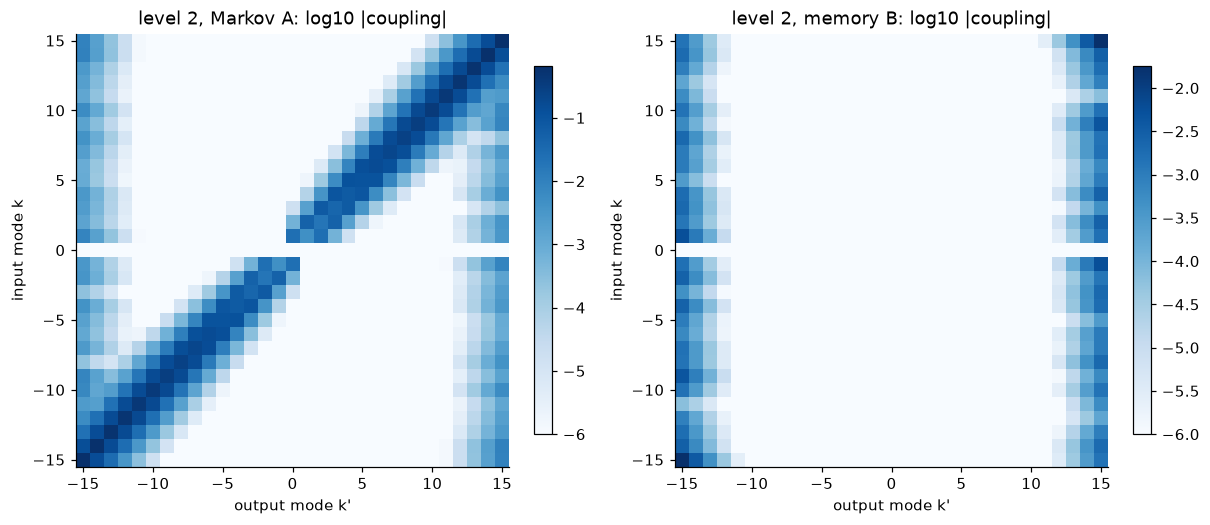

In [53]:
d = advection_data[1]  # level 2
kv = d.wavevectors[:, 0]
order = np.argsort(kv)
m = d.residual.spatial_shape[0]
k_out = 2 * np.pi * np.fft.fftfreq(m, d=d.scale[0])
order_out = np.argsort(k_out)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), constrained_layout=True)
for ax, (label, couplings) in zip(axes, [("Markov A", d.markov), ("memory B", d.memory_couplings)]):
    matrix = np.abs(couplings["I"][:, 0])[np.ix_(order, order_out)]  # (input mode, output mode)
    image = ax.imshow(np.log10(matrix + 1e-12), cmap="Blues", origin="lower", vmin=-6,
                      extent=[k_out.min() - 0.5, k_out.max() + 0.5, kv.min() - 0.5, kv.max() + 0.5])
    ax.set(xlabel="output mode k'", ylabel="input mode k", title=f"level 2, {label}: log10 |coupling|")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.85)
plt.show()

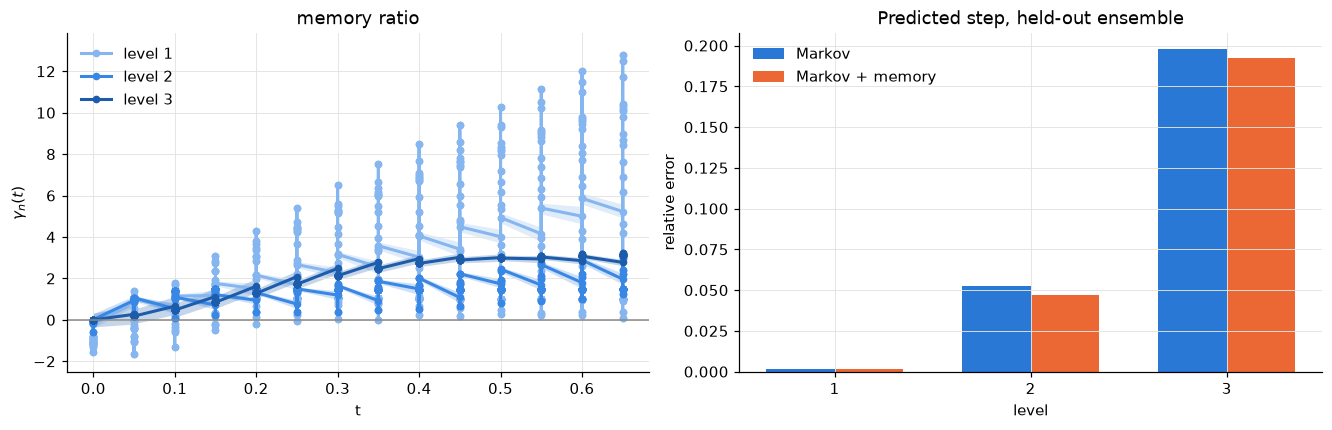

In [54]:
ratios = ratio_data(advection_data, n_bootstrap=200, seed=0)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
for level in range(1, 4):
    rows = ratios.level == level
    low, high = np.nanpercentile(ratios.bootstrap[rows].real, [5, 95], axis=1)
    left.fill_between(ratios.time[rows], low, high, color=LEVEL_COLORS[level], alpha=0.25, linewidth=0)
    left.plot(ratios.time[rows], ratios.ratio[rows].real, "o-", color=LEVEL_COLORS[level], markersize=4,
              label=f"level {level}")
left.axhline(0, color=MUTED, linewidth=1)
left.set(xlabel="t", ylabel=r"$\gamma_n(t)$", title="memory ratio")
left.legend()

levels = np.array([r["level"] for r in advection_scores])
width = 0.35
right.bar(levels - width / 2, [r["test markov"] for r in advection_scores], width, color=MARKOV, label="Markov")
right.bar(levels + width / 2, [r["test +memory"] for r in advection_scores], width, color=MEMORY,
          label="Markov + memory")
right.set(xlabel="level", ylabel="relative error", xticks=levels, title="Predicted step, held-out ensemble")
right.legend()
plt.show()

**Reading the result.** The memory term explains about a fifth of the residual's variance at levels 1-2 (21% and
19%), against 0.3-12% for Burgers. On held-out data it lowers the error at level 2 from 5.3% to 4.7%, and at level 1
from 0.18% to 0.16%. Its share falls to 5% at level 3, where $\gamma_3(t)$ also has the widest bootstrap band. The
Markov residual is far smaller than for Burgers: the dynamics is linear, so a linear map on all resolved modes
captures almost all of the step. On the low modes $|k| \le 3$ it is exact to round-off at levels 1-2 (see the summary
table): within one step, these modes only exchange energy with neighbours that are still resolved.

## 7. A lagged memory kernel

The memory term $\gamma_n(t)\, P L Q L u_n$ only uses the **current** state: $P L Q L u_n = \sum_i B_i O_i(u_n[t])$,
with $B_i$ fitted at $t = 0$. So it can only move the Markov couplings along one fixed direction,
$A_i \to A_i + \gamma_n(t) B_i$, and it never sees past states. The Mori-Zwanzig memory, though, is a sum over the
history. Here we fit the discrete-time, data-driven version of it directly:

$$
\hat u_k[t+1] - \hat u_k[t] \;=\; \sum_{s=0}^{S} \sum_i K_{s,i}(k)\, \widehat{O_i(u[t-s])}_k \;+\; \text{noise}_k[t].
$$

* $s = 0$ is the Markov term. The terms $s \ge 1$ are the memory: the past resolved states stand in for the unresolved
  modes.
* The coefficients $K$ are constant in time and fitted by least squares over the training batch and the steps
  $t \ge 3$ (so that every lag up to $S = 3$ exists). As above, Burgers uses one regression per wavevector
  (`homogeneous`), and model 3 one regression over all modes.
* $S = 0$ is the Markov model fitted on all these steps, not only at $t = 0$. Comparing $S \ge 1$ with $S = 0$ shows
  what the history adds.
* All models are scored on the held-out ensemble over the same steps, $t = 0.15$ to $0.65$: the **one-step** error,
  and a **rollout**. The rollout starts from the true states up to $t = 0.15$, steps the model on its own predictions
  (without noise), and compares with the true coarse trajectory.
* `ridge` adds a penalty on the coefficients. It is used below to stabilise one case.

In [55]:
def operator_modes(basis, values, scale):
    # Fourier modes of the operators: values (batch, [time,] space) real -> (batch, [time,] space, n_operators)
    time = None if values.ndim == 2 else np.arange(values.shape[1])
    field = Field(values=values, scale=scale, batched=True, time=time)
    return np.fft.fft(basis.stack(field).values, axis=-2)


class LaggedModel:
    # u_k[t+1] - u_k[t] = sum_{s=0..lags} sum_i K_{s,i}(k) O_i(u[t-s])_k, with coefficients constant in time, fitted by
    # least squares on the steps t >= t0: one regression per wavevector (homogeneous) or all modes at once. ridge > 0
    # adds the penalty ridge * |D c|^2, with D the rms of each regressor, so ridge is relative.

    def __init__(self, basis, lags, homogeneous=True, ridge=0.0):
        self.basis, self.lags, self.homogeneous, self.ridge = basis, lags, homogeneous, ridge

    def fit(self, c, t0):
        u = c.values
        F = operator_modes(self.basis, u, c.scale)
        t = np.arange(t0, u.shape[1] - 1)
        X = np.stack([F[:, t - s] for s in range(self.lags + 1)], axis=-2)  # (batch, steps, space, lags + 1, n_ops)
        y = np.fft.fft(u[:, t + 1] - u[:, t], axis=-1)  # (batch, steps, space)
        m = y.shape[-1]
        if self.homogeneous:
            X, y = X.reshape(-1, m, X.shape[-2] * X.shape[-1]), y.reshape(-1, m)
            self.coeffs = np.stack([self._solve(X[:, q], y[:, q]) for q in range(m)])  # (space, unknowns)
        else:
            self.coeffs = self._solve(X.reshape(-1, m * X.shape[-2] * X.shape[-1]), y.reshape(-1, m))
        return self

    def _solve(self, X, y):
        if self.ridge == 0:
            return np.linalg.lstsq(X, y, rcond=None)[0]
        # the ridge as extra rows sqrt(ridge * n) D c = 0
        penalty = np.diag(np.sqrt(self.ridge * len(X) * np.mean(np.abs(X) ** 2, axis=0)))
        zeros = np.zeros((len(penalty), *y.shape[1:]), dtype=y.dtype)
        return np.linalg.lstsq(np.concatenate([X, penalty]), np.concatenate([y, zeros]), rcond=None)[0]

    def drift(self, F_hist):
        # the step's modes from the operator modes of the last lags + 1 states, newest last: (batch, space)
        X = np.stack([F_hist[:, -1 - s] for s in range(self.lags + 1)], axis=-2)
        b, m = X.shape[:2]
        if self.homogeneous:
            return np.einsum("bmp,mp->bm", X.reshape(b, m, -1), self.coeffs)
        return X.reshape(b, -1) @ self.coeffs

    def one_step(self, c, steps):
        # predicted u[t+1] - u[t] from the true states, for the steps t: (batch, len(steps), space)
        F = operator_modes(self.basis, c.values, c.scale)
        return np.stack([np.real(np.fft.ifft(self.drift(F[:, t - self.lags : t + 1]), axis=-1)) for t in steps], axis=1)

    def rollout(self, c, t0, t1):
        # from the true states u[0..t0], step the model on its own predictions up to u[t1]: (batch, t1 - t0 + 1, space)
        u = [c.values[:, t] for t in range(t0 + 1)]
        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(t0, t1):
                F = operator_modes(self.basis, np.stack(u[-self.lags - 1 :], axis=1), c.scale)
                u.append(u[-1] + np.real(np.fft.ifft(self.drift(F), axis=-1)))
        return np.stack(u[t0:], axis=1)


def pipeline_rollout(dynamics, c, t0, t1, memory):
    # the same rollout with the EffectiveDynamics of mori_zwanzig_data, without or with the gamma(t) memory term
    u = [c.values[:, t0]]
    for t in range(t0, t1):
        state = c.replace(values=u[-1][:, None], time=c.time[t : t + 1])
        u.append(u[-1] + dynamics.evaluate(state, memory=memory).values[:, 0])
    return np.stack(u, axis=1)

In [56]:
S_MAX = 3  # the largest lag: every model is fitted and scored on the steps t >= S_MAX
T1 = N_TIME - 2  # the last state predicted: gamma(t) covers the steps up to N_TIME - 3
STEPS = np.arange(S_MAX, T1)
RIDGE = 1e-2
LAGGED = [(0, 0.0), (1, 0.0), (3, 0.0), (3, RIDGE)]  # (lags, ridge)
# line styles of the models in the plots below
STYLES = {
    "Markov, P at t = 0": dict(color=MARKOV),
    "+ gamma(t) memory": dict(color=MEMORY),
    "lagged S = 0": dict(color="#b9a6e3"),
    "lagged S = 1": dict(color="#7b5cc4"),
    "lagged S = 3": dict(color="#3d2884"),
    f"lagged S = 3, ridge {RIDGE:g}": dict(color="#3d2884", linestyle="--"),
}


def relative(predicted, true, axis=None):
    return np.linalg.norm(predicted - true, axis=axis) / np.linalg.norm(true, axis=axis)


def lagged_comparison(data, basis, train_field, test_field, homogeneous):
    # per level and model: held-out one-step error over STEPS, and rollout error at every time from TIMES[S_MAX]
    results = {}
    for d in data:
        c_train, c_test = coarse(train_field, d.level), coarse(test_field, d.level)
        true_steps = c_test.values[:, STEPS + 1] - c_test.values[:, STEPS]
        true_states = c_test.values[:, S_MAX : T1 + 1]
        states = c_test.replace(values=c_test.values[:, STEPS], time=c_test.time[STEPS])
        dynamics = d.dynamics()
        rows = {}
        for label, memory in [("Markov, P at t = 0", False), ("+ gamma(t) memory", True)]:
            rows[label] = (dynamics.evaluate(states, memory=memory).values,
                           pipeline_rollout(dynamics, c_test, S_MAX, T1, memory))
        for lags, ridge in LAGGED:
            model = LaggedModel(basis, lags, homogeneous, ridge).fit(c_train, S_MAX)
            label = f"lagged S = {lags}" + (f", ridge {ridge:g}" if ridge else "")
            rows[label] = (model.one_step(c_test, STEPS), model.rollout(c_test, S_MAX, T1))
        results[d.level] = {
            label: (relative(step, true_steps), relative(roll, true_states, axis=(0, 2)))
            for label, (step, roll) in rows.items()
        }
    return results


def show_lagged(results, title):
    print(title)
    print(f"{'level':>5}{'model':>26}{'one-step':>12}{'rollout, mean':>15}{'rollout, end':>14}")
    for level, rows in results.items():
        for label, (one_step, rollout) in rows.items():
            print(f"{level:>5}{label:>26}{one_step:>12.3g}{rollout[1:].mean():>15.3g}{rollout[-1]:>14.3g}")
    print()


lagged = {
    "Burgers, basis [u]": lagged_comparison(
        burgers_data["linear [u]"], bases["linear [u]"], train["burgers"], test["burgers"], homogeneous=True),
    "Burgers, basis [u, -(u^2/2)_x]": lagged_comparison(
        nonlinear, bases["with nonlinearity [u, -(u^2/2)_x]"], train["burgers"], test["burgers"], homogeneous=True),
    "non-uniform advection, basis [u]": lagged_comparison(
        advection_data, OperatorBasis([Identity()]), train["nonuniform advection"], test["nonuniform advection"],
        homogeneous=False),
}
for title, results in lagged.items():
    show_lagged(results, f"{title}  (held-out; steps t = {TIMES[S_MAX]:.2f} to {TIMES[T1 - 1]:.2f})")

Burgers, basis [u]  (held-out; steps t = 0.15 to 0.65)
level                     model    one-step  rollout, mean  rollout, end
    1        Markov, P at t = 0       0.857          0.336         0.451
    1         + gamma(t) memory       0.703          0.339         0.459
    1              lagged S = 0       0.715          0.336         0.441
    1              lagged S = 1       0.229          0.208         0.305
    1              lagged S = 3       0.116          0.144         0.231
    1  lagged S = 3, ridge 0.01       0.291          0.236         0.359
    2        Markov, P at t = 0       0.834          0.334         0.451
    2         + gamma(t) memory         0.7          0.337         0.459
    2              lagged S = 0       0.711          0.334          0.44
    2              lagged S = 1       0.206          0.205         0.304
    2              lagged S = 3      0.0779           0.14          0.23
    2  lagged S = 3, ridge 0.01       0.282          0.234         0.

**Reading the tables.**

* **History helps far more than $\gamma(t)$.** Burgers, nonlinear basis, level 2: one lag lowers the one-step error from
  0.127 ($S = 0$) to 0.062, three lags to 0.032, and the rollout error at $t = 0.70$ from 0.031 to 0.015. With
  $\gamma(t)$: 0.217 and 0.079. At level 4, where the most scales are removed, three lags cut the one-step error from
  0.46 to 0.014, and the rollout error at the end from 0.19 to 0.066.
* **Model 3 is the textbook case.** One lag makes level 3 essentially exact: one-step error from 0.12 to $6 \times
  10^{-6}$, rollout error at the end from 0.035 to $9 \times 10^{-4}$. The unresolved modes are driven linearly by the
  resolved ones, so a short history pins them down. At level 1, even $S = 0$ is exact to about $10^{-8}$, against
  $1.6 \times 10^{-3}$ for the Markov model with $P$ fitted at $t = 0$: that gap is the cost of fitting $P$ on the
  initial states only.
* **With the linear basis, lags help at every level** (Burgers `[u]`, level 1: one-step error from 0.715 to 0.116;
  the trajectories are compared level by level in the next subsection). This is not only memory of the unresolved
  scales. With $\Delta t = 0.05$ the trajectories are smooth in time, so
  $u[t] - u[t-1]$ already contains the previous step's nonlinear term, and lags of a linear basis partly stand in for
  the missing $-(u^2/2)_x$. The basis still matters: at level 1, the stabilised nonlinear-basis model ends its rollout
  at 0.026, the linear one at 0.23.
* **$\gamma(t)$ can even hurt a rollout:** with the basis `[u]` at levels 1-3 it raises the error at $t = 0.70$ (level
  1: from 0.45 to 0.57), although it lowers the one-step error.
* **One exception:** Burgers, nonlinear basis, level 1, with lags and no ridge. It has the best one-step error (0.027)
  but its rollout diverges (relative error about $10^{65}$ at the end), see *A good one-step fit that diverges* below.

### Linear basis: the lagged trajectory against the ratio model

The same comparison for Burgers with the basis `[u]`, at every level. Top: the relative error of the rollout over the
held-out ensemble against time. Bottom: one held-out trajectory at the end of the rollout, $t = 0.70$, on the coarse
grid of each level: the true coarse field, the model with the memory ratio $\gamma(t)$, and the lagged model with
$S = 3$.

level 1: rollout error at t = 0.70: Markov, P at t = 0 0.451,  + gamma(t) memory 0.459,  lagged S = 1 0.305,  lagged S = 3 0.231
level 2: rollout error at t = 0.70: Markov, P at t = 0 0.451,  + gamma(t) memory 0.459,  lagged S = 1 0.304,  lagged S = 3 0.230
level 3: rollout error at t = 0.70: Markov, P at t = 0 0.440,  + gamma(t) memory 0.440,  lagged S = 1 0.284,  lagged S = 3 0.205
level 4: rollout error at t = 0.70: Markov, P at t = 0 0.320,  + gamma(t) memory 0.291,  lagged S = 1 0.161,  lagged S = 3 0.105


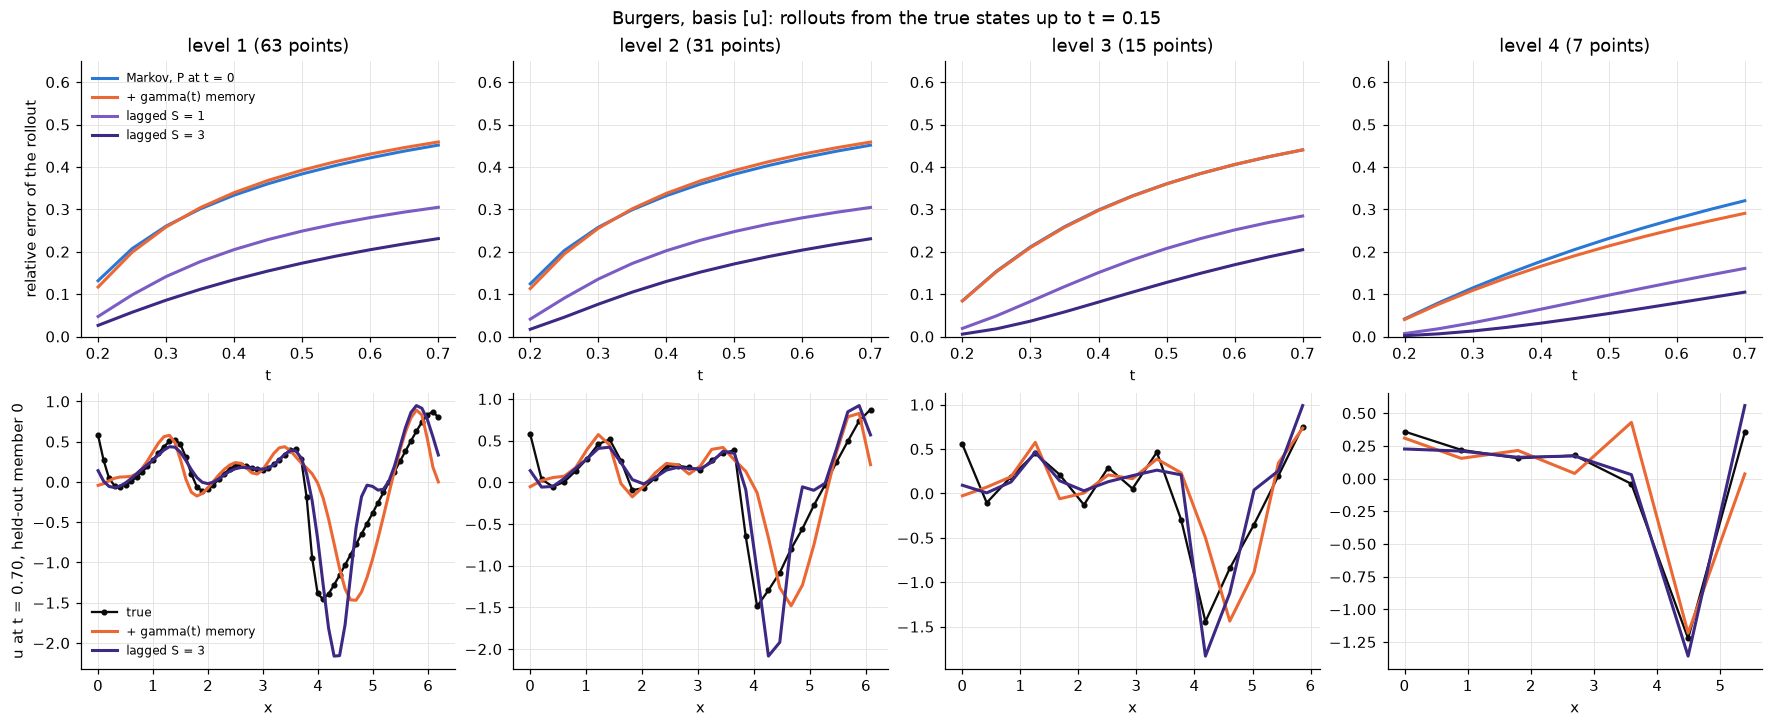

In [57]:
basis = bases["linear [u]"]
member = 0
models = ["Markov, P at t = 0", "+ gamma(t) memory", "lagged S = 1", "lagged S = 3"]
t = TIMES[S_MAX : T1 + 1]

fig, axes = plt.subplots(2, N_LEVELS, figsize=(16, 6.5), constrained_layout=True)
for col, d in enumerate(burgers_data["linear [u]"]):
    c_train, c_test = coarse(train["burgers"], d.level), coarse(test["burgers"], d.level)
    true = c_test.values[:, S_MAX : T1 + 1]
    rollouts = {
        "Markov, P at t = 0": pipeline_rollout(d.dynamics(), c_test, S_MAX, T1, memory=False),
        "+ gamma(t) memory": pipeline_rollout(d.dynamics(), c_test, S_MAX, T1, memory=True),
        "lagged S = 1": LaggedModel(basis, 1).fit(c_train, S_MAX).rollout(c_test, S_MAX, T1),
        "lagged S = 3": LaggedModel(basis, 3).fit(c_train, S_MAX).rollout(c_test, S_MAX, T1),
    }
    top, bottom = axes[0, col], axes[1, col]
    for label in models:
        top.plot(t[1:], relative(rollouts[label], true, axis=(0, 2))[1:], label=label, **STYLES[label])
    top.set(title=f"level {d.level} ({c_test.spatial_shape[0]} points)", xlabel="t", ylim=(0, 0.65))

    xc = np.arange(c_test.spatial_shape[0]) * c_test.scale[0]
    bottom.plot(xc, true[member, -1], "o-", color=TRUTH, markersize=3, linewidth=1.5, label="true")
    for label in ["+ gamma(t) memory", "lagged S = 3"]:
        bottom.plot(xc, rollouts[label][member, -1], label=label, **STYLES[label])
    bottom.set(xlabel="x")

    end = {label: relative(rollouts[label][:, -1], true[:, -1]) for label in models}
    print(f"level {d.level}: rollout error at t = {t[-1]:.2f}: " + ",  ".join(f"{k} {v:.3f}" for k, v in end.items()))
axes[0, 0].set_ylabel("relative error of the rollout")
axes[1, 0].set_ylabel(f"u at t = {t[-1]:.2f}, held-out member {member}")
axes[0, 0].legend(fontsize=8)
axes[1, 0].legend(fontsize=8)
fig.suptitle(f"Burgers, basis [u]: rollouts from the true states up to t = {t[0]:.2f}")
plt.show()

**At every level, the lagged trajectory is closer to the true one than the ratio model's.** At $t = 0.70$ the relative
error of the rollout is:

| level | Markov ($P$ at $t = 0$) | $+\,\gamma(t)$ memory | lagged $S = 1$ | lagged $S = 3$ |
|---|---|---|---|---|
| 1 | 0.451 | 0.571 | 0.305 | **0.231** |
| 2 | 0.451 | 0.566 | 0.304 | **0.230** |
| 3 | 0.440 | 0.471 | 0.284 | **0.205** |
| 4 | 0.320 | 0.292 | 0.161 | **0.105** |

The gap is there from the first step and widens with time. At levels 1-3, the ratio term even makes the rollout worse
than no memory at all; at level 4 it helps a little. The lagged models roughly halve the error of the ratio model, and
the second and third lags add to the first at every level.

The bottom row shows where the error comes from. The front of this trajectory, the steep drop near $x \approx 4$, is
where the models differ most. With $\gamma(t)$ the front is displaced by about $0.6$-$0.7$ to the right at levels 1-2, and the
field around it is distorted. The lagged model puts the front close to its true position, but overshoots it (too
deep a minimum at levels 1-3). Away from the front, both follow the true field more closely. A linear basis cannot steepen
a front, so neither model is right there; the lags, which see how the field has been moving, follow it much better.

The same holds for model 3, also with the linear basis (table above): at every level the lagged models end their
rollouts orders of magnitude closer to the truth than the ratio model.

### A good one-step fit that diverges

Below, the rollout error against time for four cases, on a log scale. Top right: without the ridge, the lagged models start below every other model, then their error grows by a constant
factor each step and leaves the plot after $t \approx 0.4$. The one-step fit only ever sees true states, so nothing in
it controls how a deviation grows once the model runs on its own output. A first check is the linear part of each
mode's recurrence, $\hat u_k[t+1] = (1 + K_0)\, \hat u_k[t] + K_1\, \hat u_k[t-1] + \dots$ (the coefficients of the
operator $u$): if its spectral radius exceeds 1, small deviations grow.

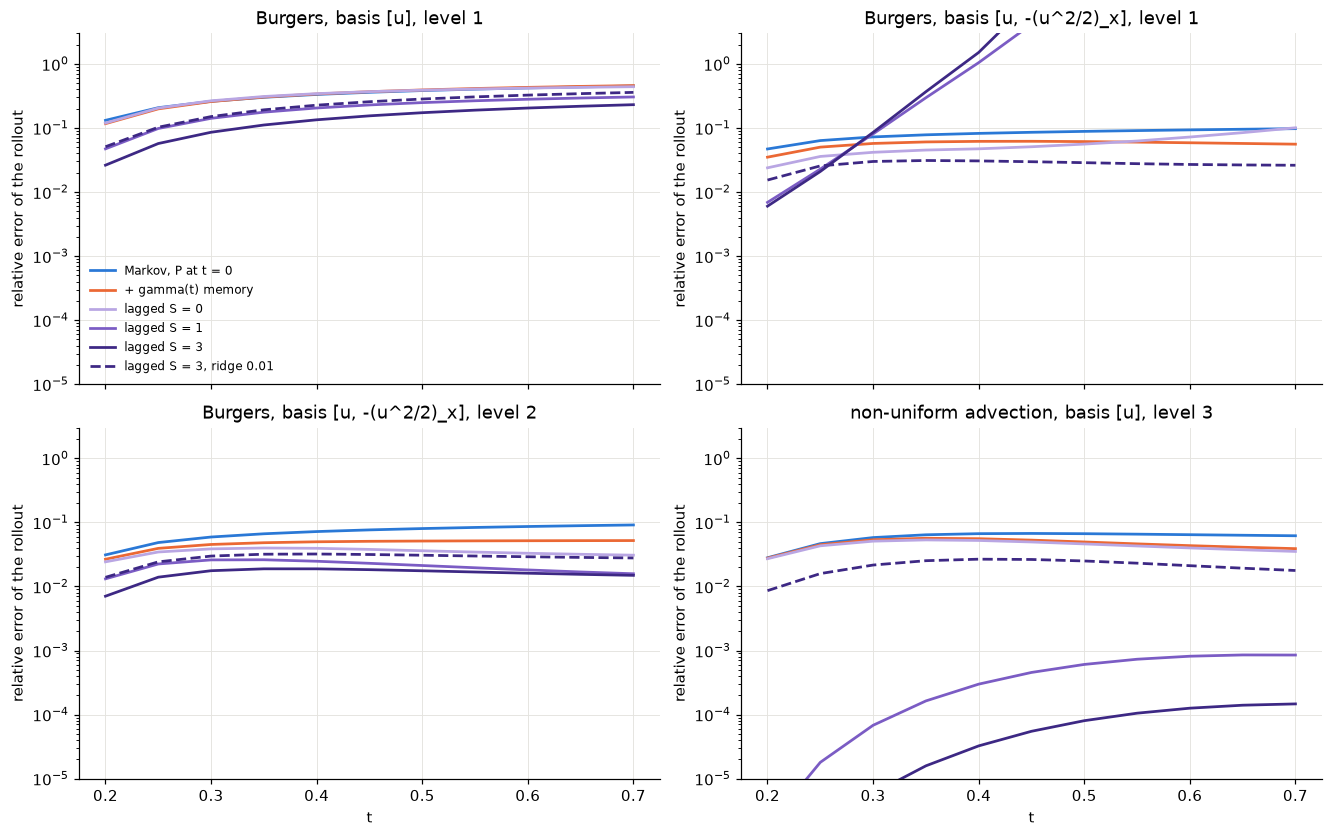

In [58]:
# relative rollout error against time, from the true states up to TIMES[S_MAX]
panels = [
    ("Burgers, basis [u]", 1),
    ("Burgers, basis [u, -(u^2/2)_x]", 1),
    ("Burgers, basis [u, -(u^2/2)_x]", 2),
    ("non-uniform advection, basis [u]", 3),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, constrained_layout=True)
t = TIMES[S_MAX : T1 + 1]
for ax, (title, level) in zip(axes.flat, panels):
    for label, (_, rollout) in lagged[title][level].items():
        ax.semilogy(t[1:], rollout[1:], linewidth=1.8, label=label, **STYLES[label])
    ax.set(title=f"{title}, level {level}", ylim=(1e-5, 3), ylabel="relative error of the rollout")
for ax in axes[1]:
    ax.set_xlabel("t")
axes[0, 0].legend(fontsize=8)
plt.show()

In [59]:
# the linear part of a lagged model is the recurrence u_k[t+1] = (1 + K_0) u_k[t] + K_1 u_k[t-1] + ... per mode; a
# spectral radius above 1 grows any deviation from the training trajectories
def spectral_radius(model):
    K = model.coeffs.reshape(len(model.coeffs), model.lags + 1, -1)[:, :, 0]  # the coefficients of u (operator I)
    radius = []
    for coeffs in K:
        companion = np.eye(model.lags + 1, k=-1, dtype=complex)
        companion[0] = coeffs
        companion[0, 0] += 1
        radius.append(np.abs(np.linalg.eigvals(companion)).max())
    return np.array(radius)


basis = bases["with nonlinearity [u, -(u^2/2)_x]"]
for level in (1, 2):
    c = coarse(train["burgers"], level)
    for lags, ridge in [(1, 0.0), (3, 0.0), (3, RIDGE)]:
        radius = spectral_radius(LaggedModel(basis, lags, ridge=ridge).fit(c, S_MAX))
        print(f"Burgers [u, -(u^2/2)_x], level {level}, S = {lags}, ridge {ridge:g}: largest spectral radius "
              f"{radius.max():.3f}, modes above 1: {np.sum(radius > 1)} of {len(radius)}")

Burgers [u, -(u^2/2)_x], level 1, S = 1, ridge 0: largest spectral radius 3.319, modes above 1: 62 of 63
Burgers [u, -(u^2/2)_x], level 1, S = 3, ridge 0: largest spectral radius 4.962, modes above 1: 62 of 63
Burgers [u, -(u^2/2)_x], level 1, S = 3, ridge 0.01: largest spectral radius 0.996, modes above 1: 0 of 63
Burgers [u, -(u^2/2)_x], level 2, S = 1, ridge 0: largest spectral radius 0.996, modes above 1: 0 of 31
Burgers [u, -(u^2/2)_x], level 2, S = 3, ridge 0: largest spectral radius 0.996, modes above 1: 0 of 31
Burgers [u, -(u^2/2)_x], level 2, S = 3, ridge 0.01: largest spectral radius 0.996, modes above 1: 0 of 31


At level 1, the linear recurrence has spectral radius above 1 on 62 of the 63 modes (up to 3.3 with one lag, 5.0
with three). On the training trajectories the lagged terms of $u$ and of $-(u^2/2)_x$ nearly cancel, but any
deviation from them grows. At level 2 every radius stays below 1 (the largest is 0.996), and the rollout is stable.
(A radius below 1 is necessary, not sufficient: the nonlinear terms also feed back.)

A relative ridge penalty of 0.01 brings level 1 below 1 as well, and gives the best level-1 rollout of all: 0.026 at
$t = 0.70$, against 0.068 with $\gamma(t)$ and 0.10 with $S = 0$. Where it is not needed, the penalty costs accuracy:
at level 2 the one-step error rises from 0.032 to 0.072, and model 3 gets worse by orders of magnitude. The value 0.01
was chosen by looking at these held-out rollouts, so its rows are somewhat optimistic. A proper choice would use a
separate validation ensemble, or the smallest penalty that keeps every radius below 1.

## 8. Summary

In [60]:
summary = {
    "heat [u]": score(heat_data, train["heat"], test["heat"]),
    "burgers [u]": burgers_scores["linear [u]"],
    "burgers [u, -(u^2/2)_x]": burgers_scores["with nonlinearity [u, -(u^2/2)_x]"],
    "nonuniform advection [u]": advection_scores,
}
columns = ["unexplained", "unexpl. |k|<=3", "memory share", "test markov", "test +memory"]
print(f"{'model':>28}{'level':>7}" + "".join(f"{c:>16}" for c in columns))
for name, rows in summary.items():
    for r in rows:
        print(f"{name:>28}{r['level']:>7}" + "".join(f"{r[c]:>16.3g}" for c in columns))

                       model  level     unexplained  unexpl. |k|<=3    memory share     test markov    test +memory
                    heat [u]      1        1.54e-15        5.28e-15           0.428        1.54e-15        1.15e-15
                    heat [u]      2        2.08e-15        7.25e-15           0.278        2.05e-15        1.74e-15
                    heat [u]      3        2.86e-15        6.87e-15           0.146        2.79e-15        2.57e-15
                    heat [u]      4        6.74e-15        6.74e-15          0.0166        6.53e-15        6.49e-15
                 burgers [u]      1           0.532           0.744           0.123           0.529           0.498
                 burgers [u]      2           0.647           0.744            0.11           0.644            0.61
                 burgers [u]      3           0.691           0.744          0.0468           0.679           0.665
                 burgers [u]      4           0.744           0.744     

**What the pipeline does on these models**

1. **Exact closures are recovered exactly.** For the heat equation, every level reproduces
   $A(k) = e^{-\nu k^2 \Delta t} - 1$ to round-off and leaves no residual.
2. **The operator basis is the first lever.** For Burgers, adding $-(u^2/2)_x$ to the basis cuts the residual on the
   low modes from 0.744 to about 0.12 at levels 1-2. With the linear basis `[u]` and `homogeneous=True`, each mode is
   fitted on its own, so the coupling and the residual of a given mode are **the same at every level**: that basis
   cannot see the cutoff at all.
3. **The cost of coarse-graining shows up on fixed modes.** With the nonlinear basis, the residual on $|k| \le 3$ grows
   from 0.11 (level 2) to 0.21 (level 3) and 0.63 (level 4), as the removed scales come closer to these modes.
   Comparing levels by their overall score mixes this effect with the change in which modes are counted.
4. **One memory ratio is a strong restriction.** $\gamma_n(t)$ is shared by every mode. It helps most when the
   unresolved modes are linearly driven by the resolved ones (model 3: about 20% of the residual at levels 1-2), and
   less for Burgers (0.3-12%).
5. **Past states carry the memory; $\gamma_n(t)$ does not.** A lagged kernel, fitted on the last 1-3 resolved states,
   beats the memory ratio everywhere once it is stable. With the linear basis, its rollouts are closer to the true
   trajectory than those of the ratio model at every level (Burgers at $t = 0.70$: 0.10-0.23 against 0.29-0.57).
   One lag makes model 3 essentially exact, and three lags cut the one-step error of Burgers (nonlinear basis) to
   1.4-3.2% at every level (section 7). Its rollouts can diverge although
   its one-step error is the best: at Burgers level 1 it needs a ridge penalty.

**Caveats**

* Everything is fitted on one transient: random-phase initial states evolving for $0.75$ time units (about 2.7 Burgers
  eddy turnover times). $P$ is fitted at $t = 0$ and applied at later times, so the couplings describe this ensemble,
  not a statistically steady state.
* Initial conditions must populate every resolved mode at $t = 0$. With a narrow initial spectrum, the Burgers fit
  diverges (section 5). The mean ($k = 0$) is zero in every state, so its couplings are meaningless; that is harmless
  only because no model changes the mean.
* `homogeneous=True` assumes statistical translation invariance (true for models 1 and 2, false for model 3).
  `homogeneous=False` needs more samples than resolved modes per level.
* `memory share` and $\gamma_n(t)$ only mean something when the residual is well above round-off (not for model 1).
* All couplings are fitted for one time step `DT`. Changing `DT` changes the couplings.

## 9. Weaknesses in `src/` found with this notebook (to check later)

1. **Near-empty modes are inverted without any safeguard.** `Projection` solves the Gram matrix of each wavevector
   with `np.linalg.pinv(self.gram, hermitian=True)` (`src/core/operators/mori_zwanzig.py`, in `coefficients`, the
   `homogeneous` branch). The cutoff of `pinv` is relative to each small per-wavevector block on its own, so a block
   whose variance at $t = 0$ is pure round-off is never truncated: it is inverted as if it were data.
   * Seen here: the $k = 0$ couplings (zero-mean initial states) are arbitrary numbers, and with the narrow initial
     spectrum the level-1 Burgers residual is about $10^{11}$ times the step, with $|A(k)|$ about $10^{12}$.
   * Nothing warns. The only check (`_projection` in `src/core/inference/mori_zwanzig.py`) compares the number of
     samples with the number of unknowns, which cannot catch this.
   * Possible fixes: a cutoff relative to the largest variance across **all** wavevectors; or a warning when a mode's
     variance at $t = 0$ is negligible; or both. This changes the method's behaviour, so it needs a decision.
2. **Not investigated: `homogeneous=True` on model 3.** In a prototype of this notebook (different parameters),
   fitting model 3 with `homogeneous=True` gave held-out errors around $10^{12}$. The model breaks translation
   invariance, so a poor fit is expected, but not one that large. It may be the same near-empty-mode problem, or
   something else.
3. **Smaller points.**
   * `EffectiveDynamics._time_indices` (`src/core/effective_theory/base.py`) matches times exactly. Floating-point
     times computed a different way, e.g. `0.1 * k` against `np.arange(0, 1, 0.1)`, may fail to match.
   * With `homogeneous=False`, the drift's Nyquist component on even grids can be nonzero (not relevant here: all
     coarse grids are odd).